# Check New `arbutus.cloud` Results of `wwatch3-nowcast` Run

Compare results of a SalishSeaCast v202111 `wwatch3-nowcast` (physics-only) run from the 2026 `arbutus.cloud`
to one from the pre-2026 `arbutus.cloud`.

The 2026 `arbutus.cloud` run uses builds from newer compilers and libraries (Ubuntu 24.04) and runs on fewer nodes.


In [1]:
import sys
from pathlib import Path

import arrow
import cmocean
import matplotlib.pyplot as plt
import xarray

Python and library versions:

In [2]:
import h5netcdf
import h5py
import matplotlib
import numpy
import pandas

print(f"Python {sys.version=}")
print(f"{numpy.__version__=}")
print(f"{xarray.__version__=}")
print(f"{pandas.__version__=}")
print(f"{h5netcdf.__version__=}")
print(f"{h5py.__version__=}")
print(f"{matplotlib.__version__=}")
print(f"{cmocean.__version__=}")
print(f"{arrow.__version__=}")

Python sys.version='3.14.6 | packaged by conda-forge | (main, Jul 24 2026, 16:09:24) [GCC 14.3.0]'
numpy.__version__='2.5.1'
xarray.__version__='2026.7.0'
pandas.__version__='3.0.5'
h5netcdf.__version__='1.8.1'
h5py.__version__='3.16.0'
matplotlib.__version__='3.11.1'
cmocean.__version__='v3.0.3'
arrow.__version__='1.4.0'


In [3]:
results_paths = {
  "baseline": Path("/opp/wwatch3/nowcast/30jun26/"),
  "new arbutus": Path("/data/dlatorne/arbutus-2026/wwatch3-nowcast/30jun26/"),
}

In [6]:
drop_vars = {
  "MAPSTA",
}

## Significant Wave Height Comparison

In [7]:
new_arbutus_ds = xarray.open_dataset(
    results_paths["new arbutus"] / "SoG_ww3_fields_20260630_20260630.nc",
    drop_variables=drop_vars, engine="h5netcdf"
)

new_arbutus_ds

<xarray.Dataset> Size: 1GB
Dimensions:    (time: 48, latitude: 661, longitude: 572)
Coordinates:
  * time       (time) datetime64[ns] 384B 2026-06-30 ... 2026-06-30T23:30:00
  * latitude   (latitude) float32 3kB 48.0 48.0 48.01 ... 50.96 50.97 50.97
  * longitude  (longitude) float32 2kB 234.0 234.0 234.0 ... 238.0 238.0 238.0
Data variables: (12/17)
    dir        (time, latitude, longitude) float32 73MB ...
    dp         (time, latitude, longitude) float32 73MB ...
    foc        (time, latitude, longitude) float32 73MB ...
    fp         (time, latitude, longitude) float32 73MB ...
    hs         (time, latitude, longitude) float32 73MB ...
    lm         (time, latitude, longitude) float32 73MB ...
    ...         ...
    vcur       (time, latitude, longitude) float32 73MB ...
    vtwo       (time, latitude, longitude) float32 73MB ...
    vuss       (time, latitude, longitude) float32 73MB ...
    vwnd       (time, latitude, longitude) float32 73MB ...
    wcc        (time, latitude, longitude) float32 73MB ...
    wch        (time, latitude, longitude) float32 73MB ...
Attributes: (12/17)
    WAVEWATCH_III_version_number:  5.16
    WAVEWATCH_III_switches:        IS0 IC0 REF1 RWND DIST MPI UQ PR3 LN1 FLX0...
    product_name:                  SoG_ww3_fields_20260630.nc
    area:                          SoG_BCgrid_00500m
    latitude_resolution:           4.50000027E-03
    longitude_resolution:          6.99999975E-03
    ...                            ...
    maximum_altitude:              9000 m
    altitude_resolution:           n/a
    start_date:                    2026-06-30 00:00:00
    stop_date:                     2026-06-30 23:30:00
    history:                       Fri Jul 31 11:40:37 2026: ncks -4 -L4 -o S...
    NCO:                           netCDF Operators version 5.2.1 (Homepage =...

In [9]:
baseline_ds = xarray.open_dataset(
    results_paths["baseline"] / "SoG_ww3_fields_20260630_20260630.nc",
    drop_variables=drop_vars, engine="h5netcdf"
)

baseline_ds

<xarray.Dataset> Size: 1GB
Dimensions:    (time: 48, latitude: 661, longitude: 572)
Coordinates:
  * time       (time) datetime64[ns] 384B 2026-06-30 ... 2026-06-30T23:30:00
  * latitude   (latitude) float32 3kB 48.0 48.0 48.01 ... 50.96 50.97 50.97
  * longitude  (longitude) float32 2kB 234.0 234.0 234.0 ... 238.0 238.0 238.0
Data variables: (12/17)
    dir        (time, latitude, longitude) float32 73MB ...
    dp         (time, latitude, longitude) float32 73MB ...
    foc        (time, latitude, longitude) float32 73MB ...
    fp         (time, latitude, longitude) float32 73MB ...
    hs         (time, latitude, longitude) float32 73MB ...
    lm         (time, latitude, longitude) float32 73MB ...
    ...         ...
    vcur       (time, latitude, longitude) float32 73MB ...
    vtwo       (time, latitude, longitude) float32 73MB ...
    vuss       (time, latitude, longitude) float32 73MB ...
    vwnd       (time, latitude, longitude) float32 73MB ...
    wcc        (time, latitude, longitude) float32 73MB ...
    wch        (time, latitude, longitude) float32 73MB ...
Attributes: (12/17)
    WAVEWATCH_III_version_number:  5.16
    WAVEWATCH_III_switches:        IS0 IC0 REF1 RWND DIST MPI UQ PR3 LN1 FLX0...
    product_name:                  SoG_ww3_fields_20260630.nc
    area:                          SoG_BCgrid_00500m
    latitude_resolution:           4.50000027E-03
    longitude_resolution:          6.99999975E-03
    ...                            ...
    maximum_altitude:              9000 m
    altitude_resolution:           n/a
    start_date:                    2026-06-30 00:00:00
    stop_date:                     2026-06-30 23:30:00
    history:                       Tue Jun 30 10:12:20 2026: ncks -4 -L4 -o S...
    NCO:                           4.7.2

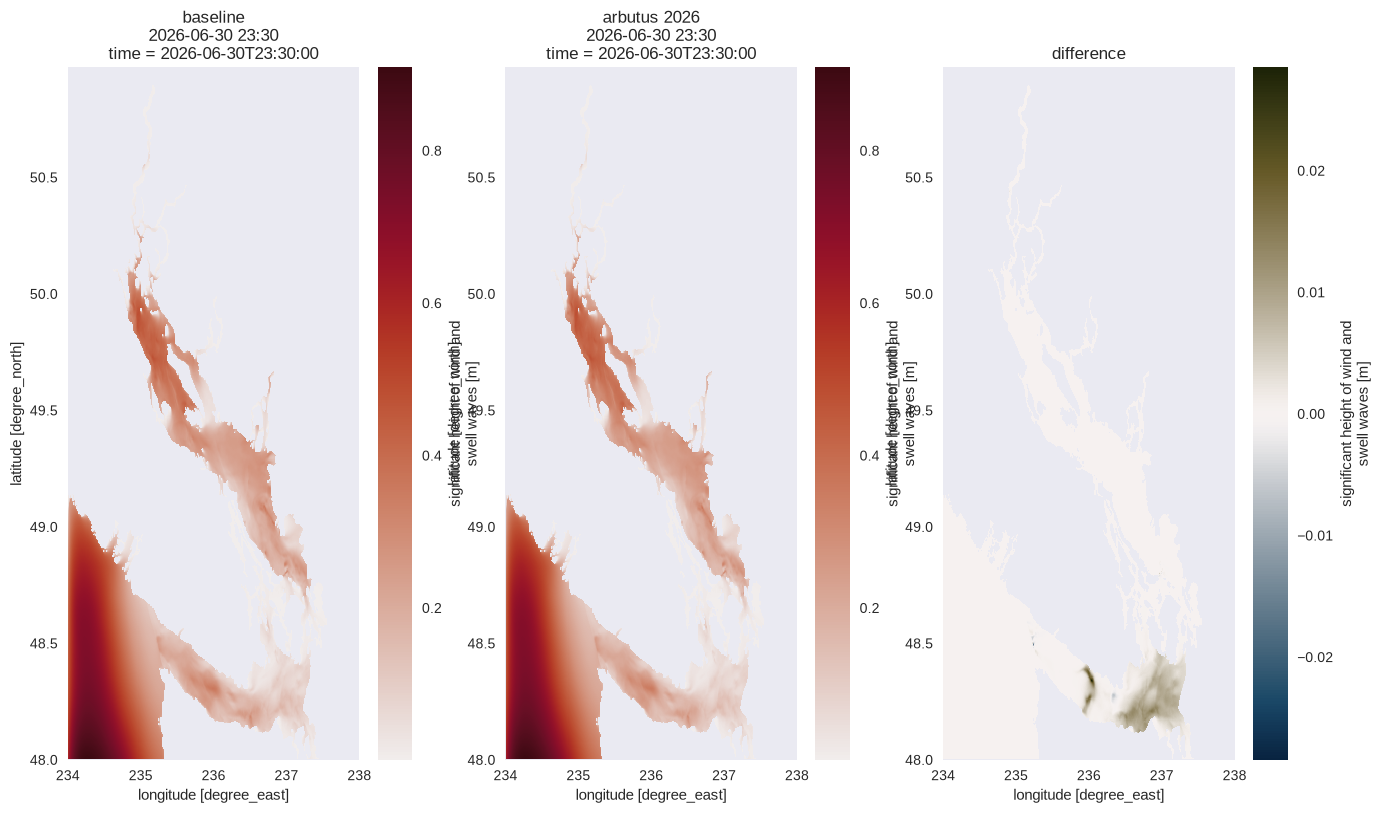

In [12]:
_, (axref, axcomp, axdiff) = plt.subplots(1, 3, figsize=(16, 9))
timestamp = arrow.get(pandas.to_datetime(baseline_ds.time)[-1]).format("YYYY-MM-DD HH:mm")

baseline_hs = baseline_ds.hs.isel(time=-1)
baseline_hs.plot(ax=axref, cmap=cmocean.cm.amp)
axref.set_title(f"baseline\n{timestamp}\n{axref.get_title().split(",")[0]}")

new_arbutus_hs = new_arbutus_ds.hs.isel(time=-1)
new_arbutus_hs.plot(ax=axcomp, cmap=cmocean.cm.amp)
axcomp.set_title(f"arbutus 2026\n{timestamp}\n{axcomp.get_title().split(",")[0]}")

(baseline_hs - new_arbutus_hs).plot(ax=axdiff, cmap=cmocean.cm.diff)
axdiff.set_title("difference");

In [13]:
xarray.ufuncs.abs((baseline_hs - new_arbutus_hs)).max().item()

0.028495803475379944

Nearly identical significant wave height fields indicate that the `nowcast-blue` (physics-only) run from the 2026 `arbutus.cloud`
is equivalent to the one from the pre-2026 `arbutus.cloud`.